# 09 · Plotting

Two functions, also available as methods (`s.plot()`, `c.plot()`):

- `stk.plot(*data, kind=...)` draws spectra and collections: `"lines"` (default), `"stack"`, `"mean"` (mean ± 1 SD), `"image"` (one row per spectrum).
- `stk.compare(before, after, index)` shows what one processing step did, with a "removed" panel underneath.

Common settings: `region=(lo, hi)`, `xlabel=`, `title=`, `invert_x=True`, `style="clean"` (default) / `"publication"`, `save="figure.png"`. Every call returns the matplotlib `ax`, so anything can be changed afterwards.

In [1]:
import matplotlib.pyplot as plt
import spectrum_toolkit as stk
from spectrum_toolkit.plot import KINDS

cv = stk.load('../data/CV10-4M.xlsx', verbose=False)
wt = stk.load('../data/wt_raw.mat', verbose=False).trim(441, 1818)
clean = cv.despike(verbose=False).baseline()
XL = 'Raman shift (cm⁻¹)'

## 1. Kinds of plot

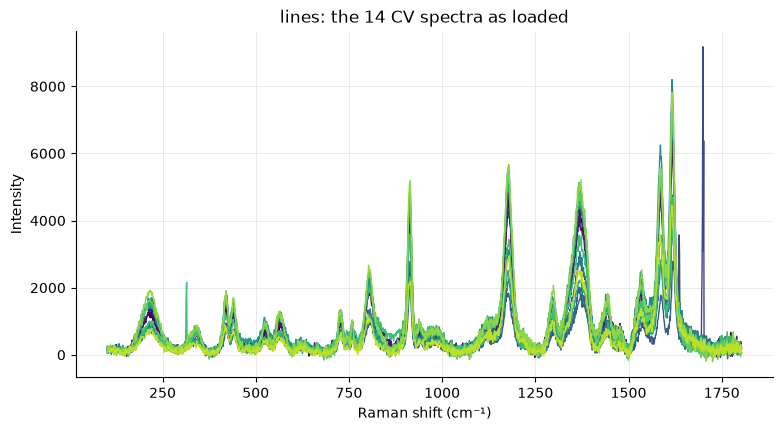

In [2]:
cv.plot(xlabel=XL, title='lines: the 14 CV spectra as loaded');

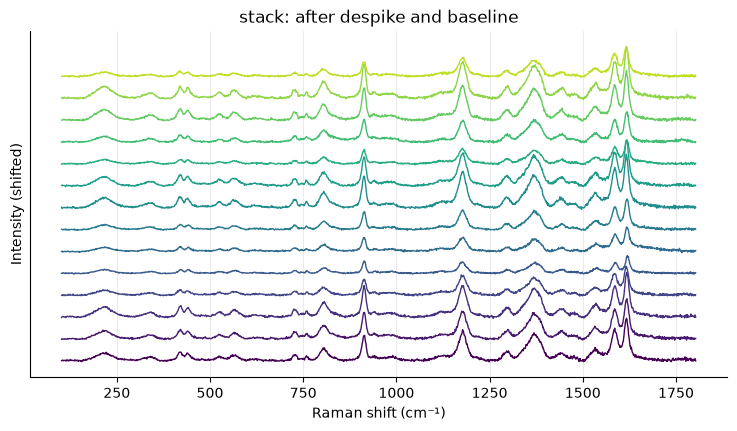

In [3]:
clean.plot('stack', xlabel=XL, title='stack: after despike and baseline');

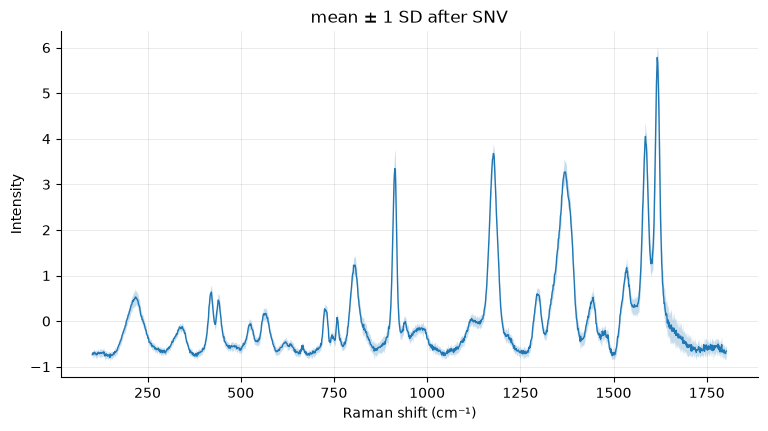

In [4]:
stk.plot(clean.normalize(), kind='mean', labels=['CV'], xlabel=XL, title='mean ± 1 SD after SNV');

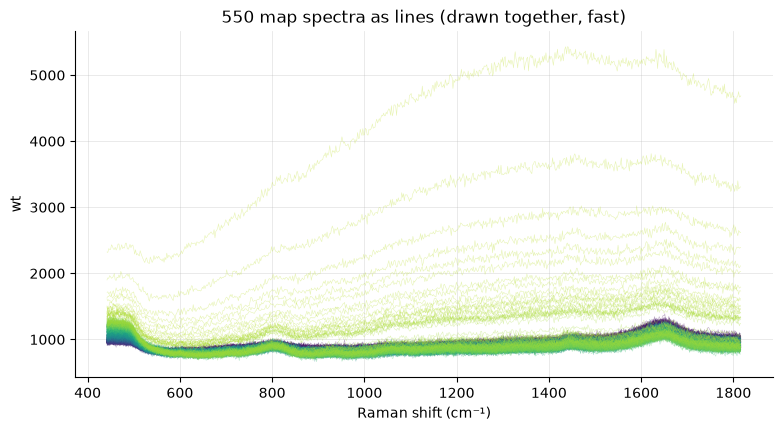

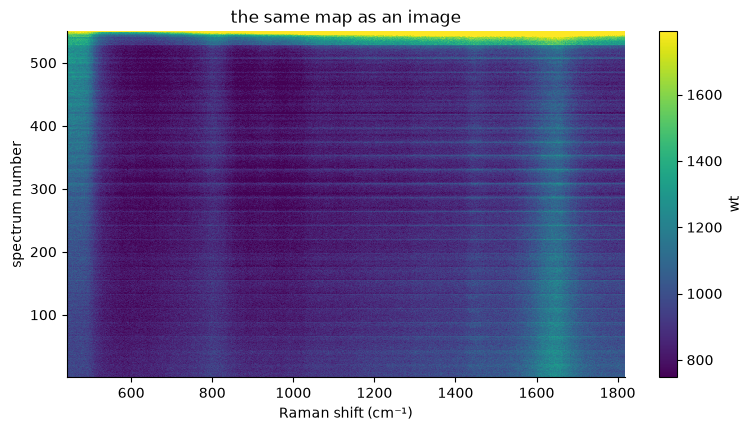

In [5]:
wt.plot(xlabel=XL, title='550 map spectra as lines (drawn together, fast)')
wt.plot('image', xlabel=XL, title='the same map as an image');

## 2. Before and after a step

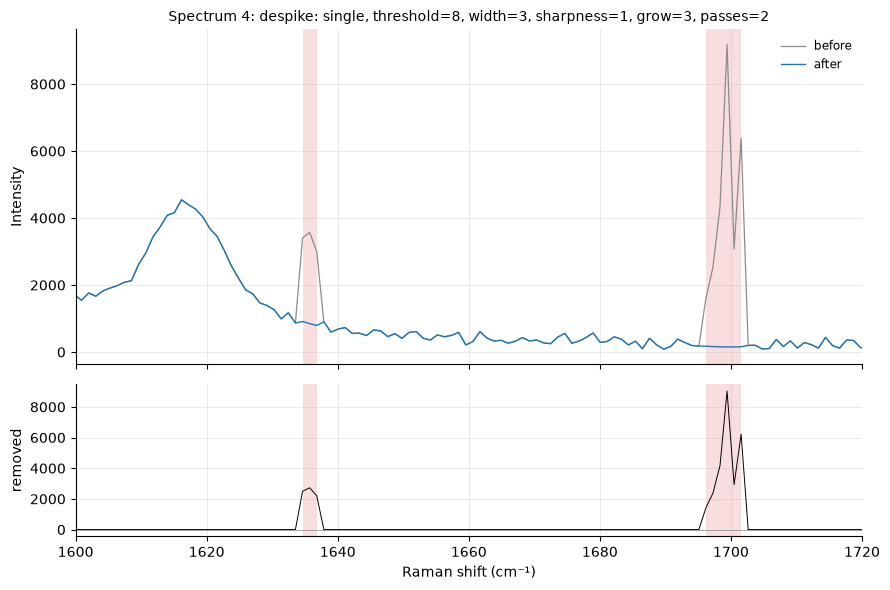

In [6]:
d = cv.despike(verbose=False)
stk.compare(cv, d, 'Spectrum 4', region=(1600, 1720), xlabel=XL);

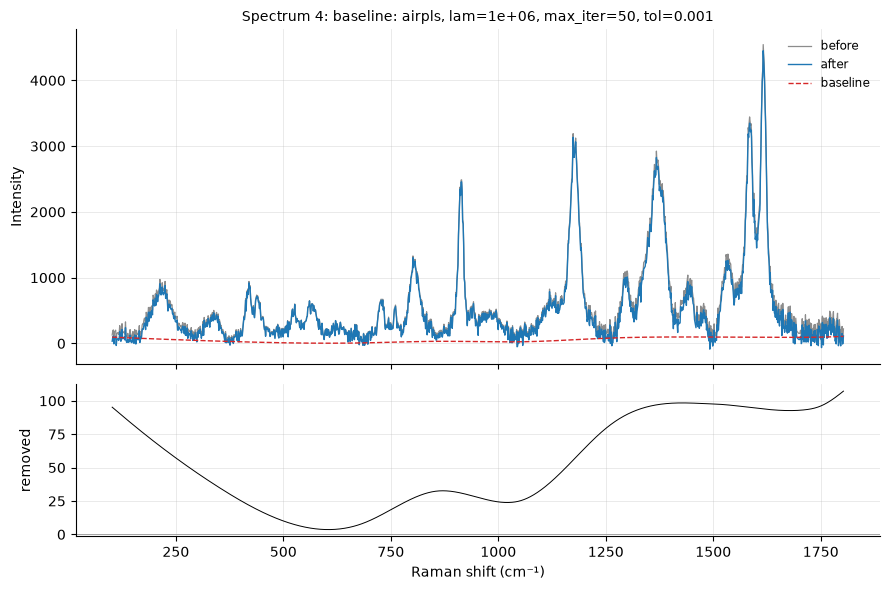

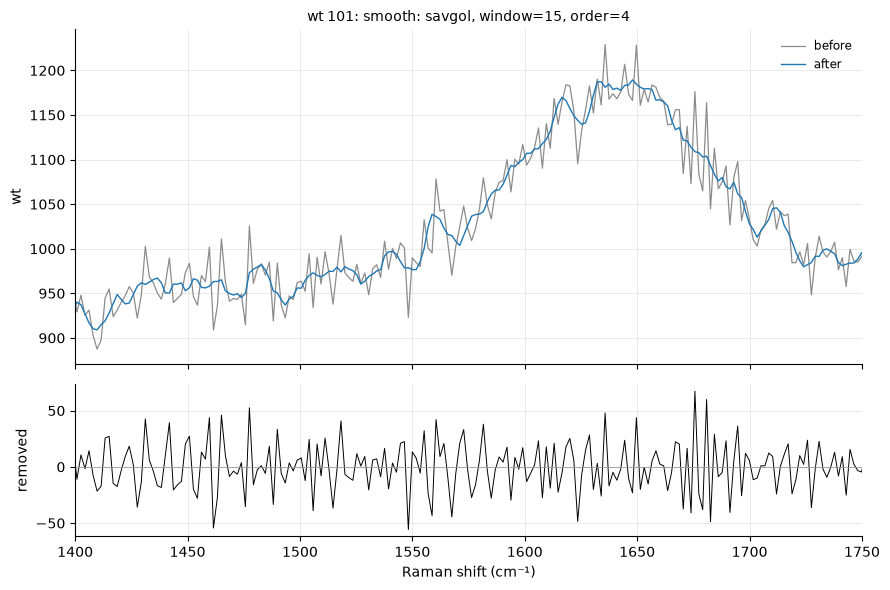

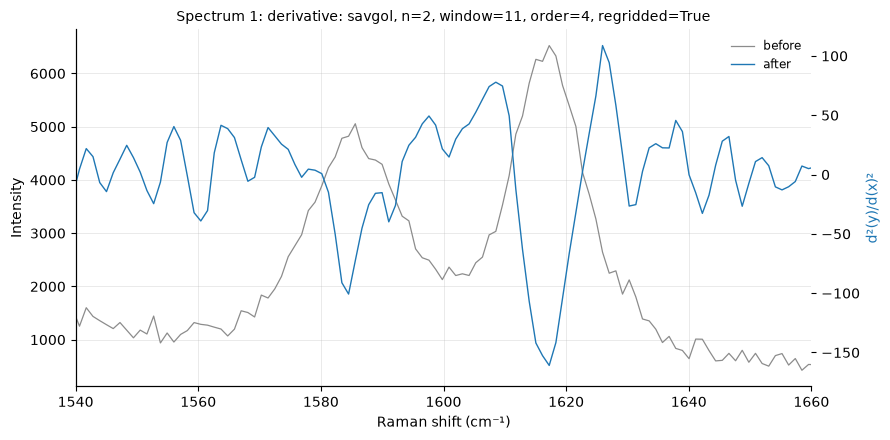

In [7]:
stk.compare(d, d.baseline(), 3, xlabel=XL)
stk.compare(wt, wt.smooth(), 100, region=(1400, 1750), xlabel=XL)
stk.compare(d, d.derivative(n=2), 0, region=(1540, 1660), xlabel=XL);

## 3. Play with the settings

In [8]:
from ipywidgets import interact, Dropdown, FloatRangeSlider, Checkbox

steps = {'despike': lambda c: c.despike(verbose=False), 'baseline': lambda c: c.baseline(),
         'smooth': lambda c: c.smooth(), 'normalize': lambda c: c.normalize(), 'derivative n=2': lambda c: c.derivative(n=2)}
base = cv.despike(verbose=False)

def show(view='plot', kind='lines', step='baseline', spectrum='Spectrum 4', region=(100, 1800), style='clean', invert=False):
    if view == 'plot':
        clean.plot(kind, region=region, style=style, invert_x=invert, xlabel=XL)
    else:
        before = cv if step == 'despike' else base
        stk.compare(before, steps[step](before), spectrum, region=region, style=style, invert_x=invert, xlabel=XL)
    plt.show()

interact(show, view=Dropdown(options=['plot', 'compare']), kind=Dropdown(options=KINDS),
         step=Dropdown(options=list(steps)), spectrum=Dropdown(options=cv.names),
         region=FloatRangeSlider(value=(100, 1800), min=100, max=1800, step=10),
         style=Dropdown(options=['clean', 'publication', 'matplotlib']));

interactive(children=(Dropdown(description='view', options=('plot', 'compare'), value='plot'), Dropdown(descri…

## 4. Saving for a paper

In [ ]:
ax = clean.plot('stack', style='publication', xlabel=XL, region=(400, 1700))
ax.set_title('CV, 14 spots')
# ax.figure.savefig('cv_stack.png', dpi=300, bbox_inches='tight')   # or: clean.plot(..., save='cv_stack.png')